# SiteWise · Construcción del dataset municipal v0.1

**Autora del trabajo de datos: Elena y equipo SiteWise · Preparación: 13 de noviembre de 2026.**

Este notebook realiza la extracción, limpieza, transformación y carga a ficheros de una primera base nacional para comparar ubicaciones empresariales. Cada fila final representa un municipio; cada valor mantiene su fuente, periodo y escala real. Es un notebook de ETL explicado, no un modelo de recomendación terminado.

**Entrega:** `municipios`, `indicadores`, `valores`, una tabla ancha, geometrías y controles de calidad. Los resultados comprobados aparecen al final tras ejecutar todas las celdas.

**Regla del equipo:** se aceptan datos municipales y provinciales. Los provinciales se repiten a todos sus municipios y se etiquetan `aproximado`. Las tablas autonómicas y nacionales quedan excluidas como indicadores. Los nombres de CCAA se usan solo como identificación territorial.

**Límite importante:** todavía faltan recurso solar, carreteras, terminales de mercancías, agua y suelo industrial, entre otros. Esta versión permite integrar y explorar datos reales; no permite declarar una ubicación apta para una actividad ni calcular una nota de riesgo compuesto validada.

## 1 · Preparar el entorno y localizar el proyecto

Descomprime el paquete **en la raíz del repositorio** (`C:\PROYECTOS_ELE\Final_sidewise`), conservando `notebooks/`, `data/` y `docs/`. Abre este archivo desde `notebooks/` y selecciona el kernel `.venv`.

En PowerShell, desde la raíz y con `.venv` activado:

```powershell
python -m pip install -r requirements.txt
```

El código no fija una ruta de mi ordenador. Detecta la raíz desde la carpeta actual; si trabajas desde otra ubicación, define `SITEWISE_PROJECT_ROOT`. El ZIP incluye las fuentes y permite ejecutar sin volver a descargarlas. No hace falta Microsoft Access para esta ejecución.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, io, re, unicodedata, platform, sys
from urllib.request import urlopen, Request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import shape, mapping
from shapely import make_valid
from IPython.display import display, Markdown

candidatos = [Path(os.environ['SITEWISE_PROJECT_ROOT'])] if os.environ.get('SITEWISE_PROJECT_ROOT') else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p / 'notebooks').is_dir() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abre el notebook dentro del proyecto o define SITEWISE_PROJECT_ROOT.')
RAW = ROOT / 'data/raw/sitewise_v01'
OUT = ROOT / 'data/processed/sitewise_v01'
QA = ROOT / 'docs/data/sitewise_v01'
OUT.mkdir(parents=True, exist_ok=True)
QA.mkdir(parents=True, exist_ok=True)
manifest = json.loads((RAW / 'manifest_fuentes.json').read_text(encoding='utf-8'))
FUENTES = manifest['fuentes']
incidencias = []
cruces = []
pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 16)
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Proyecto:', ROOT)
print('Python:', platform.python_version(), '| pandas:', pd.__version__)
print('Fuentes:', len(FUENTES), '| Corte del proyecto:', manifest['fecha_corte_proyecto'])

Proyecto: c:\PROYECTOS_ELE\Final_sidewise
Python: 3.14.6 | pandas: 2.3.3
Fuentes: 7 | Corte del proyecto: 2026-11-13


## 2 · Fuentes y trazabilidad

Usamos fuentes primarias: INE, ministerios y Eurostat/GISCO. No se han usado datos simulados ni un dataset genérico de terceros.

La fecha de descarga no es la fecha del dato. Mezclamos población 2024–2025, cobertura de junio de 2025, electricidad 2021, incendios 2006–2015 y registros históricos de inundaciones seleccionados en 2000–2023. **No son un panel sincrónico de 2026.** Cada indicador conserva su periodo.

El archivo `manifest_fuentes.json` registra enlaces, tamaños y SHA-256. Estos hashes identifican exactamente los bytes utilizados: si el proveedor actualiza un fichero, el notebook exige revisarlo antes de mezclar versiones. Los CSV de CNIH son exportaciones sin filtrar del Access oficial; no se han escrito observaciones a mano.

Los límites municipales GISCO son cartografía generalizada. Se incluye atribución © EuroGeographics y deben respetarse sus condiciones de descarga/reutilización, especialmente antes de un uso comercial. La revisión jurídica de las licencias específicas no se considera cerrada por haber descargado datos públicos.

In [2]:
catalogo_fuentes = pd.DataFrame.from_dict(FUENTES, orient='index').rename_axis('fuente_id').reset_index()
display(catalogo_fuentes[['fuente_id', 'organismo', 'periodo', 'nivel']])

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

def descargar(url, destino, hash_esperado=None):
    """Descarga acotada y valida el archivo antes de aceptarlo."""
    destino = Path(destino)
    temporal = destino.with_suffix(destino.suffix + '.part')
    try:
        with urlopen(Request(url, headers={'User-Agent': 'SiteWise-ETL/0.1'}), timeout=120) as r, temporal.open('wb') as f:
            while bloque := r.read(1024 * 1024):
                f.write(bloque)
        if hash_esperado and sha256(temporal) != hash_esperado:
            raise ValueError(f'La fuente ha cambiado: {destino.name}. Revisar esquema y versión antes de aceptar.')
        temporal.replace(destino)
    finally:
        temporal.unlink(missing_ok=True)
    return destino

# Recuperar solo entradas directas que falten. No refrescar silenciosamente la instantánea.
for fuente in FUENTES.values():
    nombre = fuente['archivo']
    if '*' not in nombre and fuente is not FUENTES['gisco'] and not (RAW / nombre).exists():
        descargar(fuente['url'], RAW / nombre, manifest['archivos'][nombre]['sha256'])

faltantes = [n for n in manifest['archivos'] if not (RAW / n).exists()]
if faltantes:
    raise FileNotFoundError(f'Faltan entradas del paquete: {faltantes}. Usa el ZIP completo o reconstruye las exportaciones del apartado final.')
verificacion = pd.DataFrame([{'archivo': n, 'bytes': (RAW/n).stat().st_size,
    'hash_correcto': sha256(RAW/n) == meta['sha256']} for n, meta in manifest['archivos'].items()])
assert verificacion.hash_correcto.all(), 'Hay fuentes modificadas. Revisar antes de continuar.'
print(f'{len(verificacion)} archivos de entrada verificados por SHA-256.')

,fuente_id,organismo,periodo,nivel
0,ine_municipios,INE,2026-01-01,municipio
1,ine_poblacion,INE,2024-01-01 y 2025-01-01,municipio
2,cobertura,Ministerio para la Transformación Digital y de...,"2025-06; referencia hogar censo 2021, base geo...",municipio
3,electricidad,MITECO / GECOS,2021,provincia
4,egif,MITECO / EGIF,2006-2015,municipio
5,cnih,MITECO / Dirección General del Agua,Se seleccionan registros fechados 2000-2023; c...,municipio
6,gisco,Eurostat / GISCO,2024-01-01,municipio


66 archivos de entrada verificados por SHA-256.


## 3 · Base oficial de municipios

Leemos las 52 hojas provinciales del INE. En cada hoja las primeras dos filas son títulos: se excluyen antes de trabajar con los datos. El código municipal se forma con **CPRO (2 dígitos) + CMUN (3 dígitos)**; el dígito de control DC no pertenece al código de cinco posiciones.

Conservar los códigos como texto evita perder ceros iniciales. El universo se fija con el INE de 1 de enero de 2026 y los cruces posteriores serán `left join`: una fuente incompleta nunca eliminará municipios del dataset.

In [3]:
def codigo_ine(serie):
    # Algunos CSV exportados de Access representan códigos enteros como 1001.0.
    s = serie.astype('string').str.strip().str.replace(r'\.0+$', '', regex=True)
    valido = s.str.fullmatch(r'\d{1,5}', na=False)
    return s.where(valido).str.zfill(5)

libro = pd.ExcelFile(RAW / '26codmun.xlsx')
partes = []
for hoja in libro.sheet_names:
    titulo = pd.read_excel(libro, sheet_name=hoja, header=None, nrows=2)
    tabla = pd.read_excel(libro, sheet_name=hoja, header=2, dtype=str)
    assert {'CPRO', 'CMUN', 'NOMBRE', 'DC'} <= set(tabla.columns)
    tabla['provincia'] = str(titulo.iloc[1, 0]).strip()
    partes.append(tabla)
municipios = pd.concat(partes, ignore_index=True)
municipios['cod_provincia'] = municipios.CPRO.str.zfill(2)
municipios['cod_ine'] = municipios.cod_provincia + municipios.CMUN.str.zfill(3)
municipios = municipios.rename(columns={'NOMBRE': 'nombre'})[['cod_ine', 'nombre', 'cod_provincia', 'provincia']]
assert municipios.cod_ine.str.fullmatch(r'\d{5}').all()
assert municipios.cod_ine.is_unique
assert municipios.nombre.notna().all()
N = len(municipios)
print('Municipios oficiales:', N, '| Provincias y ciudades autónomas:', municipios.cod_provincia.nunique())
display(municipios.head())

def auditar_cruce(nombre, tabla, clave='cod_ine'):
    assert tabla[clave].is_unique, f'{nombre}: la clave no es única; no se permite multiplicar filas.'
    base = municipios[clave] if clave == 'cod_ine' else municipios[clave].drop_duplicates()
    extras = tabla.loc[~tabla[clave].isin(base)]
    cruces.append({'fuente': nombre, 'clave': clave, 'filas_fuente': len(tabla),
                   'claves_base': len(base), 'sin_dato_en_fuente': int((~base.isin(tabla[clave])).sum()),
                   'claves_fuera_base': len(extras)})
    if len(extras):
        extras.to_csv(QA / f'claves_no_cruzadas_{nombre}.csv', index=False, encoding='utf-8-sig')

def normalizar_nombre(nombre):
    s = unicodedata.normalize('NFKD', str(nombre)).encode('ascii', 'ignore').decode().lower().strip()
    if ',' in s:
        resto, articulo = s.rsplit(',', 1)
        if articulo.strip() in {'el','la','los','las','a','o','os','as',"l'",'es','sa','ses','els','les'}:
            s = articulo.strip() + ' ' + resto.strip()
    return re.sub(r'[^a-z0-9]+', ' ', s).strip()

def aliases_nombre(nombre):
    if pd.isna(nombre):
        return set()
    return {normalizar_nombre(nombre)} | {normalizar_nombre(parte) for parte in str(nombre).split('/')}

nombre_por_codigo = municipios.set_index('cod_ine').nombre.to_dict()
indice_nombres = {}
for fila in municipios.itertuples(index=False):
    for alias in aliases_nombre(fila.nombre):
        indice_nombres.setdefault((fila.cod_provincia, alias), set()).add(fila.cod_ine)

def comprobar_denominaciones(tabla, columna_nombre, fuente):
    audit = tabla[['cod_ine',columna_nombre]].copy().rename(columns={columna_nombre:'nombre_fuente'})
    audit['nombre_ine_2026'] = audit.cod_ine.map(nombre_por_codigo)
    audit['coincide_nombre_normalizado'] = [bool(aliases_nombre(a) & aliases_nombre(b)) for a,b in zip(audit.nombre_fuente,audit.nombre_ine_2026)]
    audit.loc[~audit.coincide_nombre_normalizado].to_csv(QA / f'denominaciones_distintas_{fuente}.csv',index=False,encoding='utf-8-sig')
    return int((~audit.coincide_nombre_normalizado).sum())


Municipios oficiales: 8132 | Provincias y ciudades autónomas: 52


,cod_ine,nombre,cod_provincia,provincia
0,01051,Agurain/Salvatierra,01,Araba/Álava
1,01001,Alegría-Dulantzi,01,Araba/Álava
2,01002,Amurrio,01,Araba/Álava
3,01049,Añana,01,Araba/Álava
4,01003,Aramaio,01,Araba/Álava


## 4 · Cobertura digital municipal

Se lee únicamente `Municipio_%hogar`. Se descartan las hojas de CCAA y los agregados nacionales; tampoco se mezclan porcentajes sobre viviendas con porcentajes sobre hogares.

En Excel los valores están guardados como fracciones 0–1. Se convierten a porcentajes 0–100. Una tolerancia de **una millonésima en la fracción** solo permite corregir errores de coma flotante en los límites; cualquier exceso mayor detiene el proceso. Cada corrección queda registrada.

La columna de habitantes del fichero de cobertura no se usa como población actual: su referencia es INE 2024. La población vendrá de su fuente oficial propia. Fibra doméstica o 5G en hogares no garantizan conectividad contratada en un polígono industrial.

In [4]:
cob = pd.read_excel(RAW / 'cobertura_2021_2025.xlsx', sheet_name='Municipio_%hogar', dtype={'CMUN': str})
cob['cod_ine'] = codigo_ine(cob.CMUN)
assert cob.cod_ine.notna().all() and cob.cod_ine.is_unique
columnas_cob = {
    'cobertura_ftth_pct': 'FTTH \n(junio 2025)',
    'cobertura_100mbps_pct': 'Cob. 100Mbps condiciones máxima demanda\n(junio 2025)',
    'cobertura_1gbps_pct': 'Cob. 1Gbps descarga condiciones máxima demanda\n(junio 2025)',
    'cobertura_5g_pct': '5G\n(junio 2025)',
}
cob_limpia = cob[['cod_ine', 'Comunidad Autónoma']].rename(columns={'Comunidad Autónoma': 'ccaa'})
for indicador, columna in columnas_cob.items():
    s = pd.to_numeric(cob[columna], errors='raise')
    assert ((s.isna()) | s.between(-1e-6, 1 + 1e-6)).all(), f'Cobertura fuera de rango: {indicador}'
    correcciones = s.notna() & ~s.between(0, 1)
    for idx in s.index[correcciones]:
        incidencias.append({'fuente': 'cobertura', 'cod_ine': cob.loc[idx, 'cod_ine'],
            'campo': indicador, 'problema': 'exceso_numerico_marginal',
            'valor_original': float(s.loc[idx]), 'accion': 'limitar_a_0_1_antes_de_convertir_a_porcentaje'})
    cob_limpia[indicador] = s.clip(0, 1) * 100
assert cob_limpia.ccaa.notna().all()
auditar_cruce('cobertura', cob_limpia)
municipios = municipios.merge(cob_limpia[['cod_ine', 'ccaa']], on='cod_ine', how='left', validate='one_to_one')
display(cob_limpia[['cod_ine', *columnas_cob]].head())
print('Correcciones de precisión:', len(incidencias))
print('Denominaciones de cobertura distintas a INE 2026, conservadas por código oficial:', comprobar_denominaciones(cob, 'Municipio', 'cobertura'))

,cod_ine,cobertura_ftth_pct,cobertura_100mbps_pct,cobertura_1gbps_pct,cobertura_5g_pct
0,01001,98.776224,98.776224,98.776224,68.958003
1,01002,95.017964,95.449102,95.041916,100.000000
2,01003,86.751361,91.288566,86.751361,99.840710
3,01004,95.799458,97.967480,95.799458,100.000000
4,01006,80.208333,80.208333,80.208333,97.975747


Correcciones de precisión: 1935
Denominaciones de cobertura distintas a INE 2026, conservadas por código oficial: 9


## 5 · Población y evolución demográfica

Se descargaron las 52 tablas provinciales del padrón mediante la API pública del INE con metadatos (`tip=AM`) y los dos últimos años disponibles (`nult=2`). El paquete congela esos resultados en 2024 y 2025.

Aunque los archivos están separados por provincia, contienen datos **municipales**. Extraemos el código INE desde `MetaData`, no de la posición de la fila ni del nombre. Seleccionamos sexo `Total` y nivel `Municipios`; las filas totales provinciales quedan fuera.

Variación anual = `(población 2025 / población 2024 - 1) × 100`. Sirve para describir evolución, no para medir directamente personal cualificado ni disponibilidad laboral. No se inventa una tasa cuando el denominador es cero o falta.

In [5]:
poblacion_filas = []
for archivo in sorted(RAW.glob('ine_poblacion_*.json')):
    tabla_id = archivo.stem.rsplit('_', 1)[-1]
    for serie in json.loads(archivo.read_text(encoding='utf-8')):
        meta = {m['T3_Variable']: m for m in serie['MetaData']}
        if meta.get('Sexo', {}).get('Nombre') != 'Total':
            continue
        mun = meta.get('Municipios', {})
        if not re.fullmatch(r'\d{5}', mun.get('Codigo', '')):
            continue  # Excluir los totales provinciales.
        for dato in serie['Data']:
            if int(dato['Anyo']) in (2024, 2025):
                poblacion_filas.append({'cod_ine': mun['Codigo'], 'anio': int(dato['Anyo']),
                    'poblacion': dato['Valor'], 'tabla_ine': tabla_id, 'nombre_fuente': mun['Nombre']})
poblacion_larga = pd.DataFrame(poblacion_filas)
assert not poblacion_larga.duplicated(['cod_ine', 'anio']).any()
assert poblacion_larga.poblacion.dropna().ge(0).all()
pob = poblacion_larga.pivot(index='cod_ine', columns='anio', values='poblacion').rename(columns={2024: 'poblacion_2024', 2025: 'poblacion_2025'}).reset_index()
pob.columns.name = None
pob['variacion_poblacion_pct'] = (pob.poblacion_2025 / pob.poblacion_2024.where(pob.poblacion_2024.gt(0)) - 1) * 100
pob['tabla_ine'] = poblacion_larga.groupby('cod_ine').tabla_ine.first().reindex(pob.cod_ine).to_numpy()
auditar_cruce('poblacion', pob)
print('Reconciliación de población municipal (suma; no confundir padrón con Censo Anual):')
display(poblacion_larga.groupby('anio').agg(municipios=('cod_ine', 'nunique'), habitantes=('poblacion', 'sum')))
display(pob.head())

Reconciliación de población municipal (suma; no confundir padrón con Censo Anual):


,municipios,habitantes
anio,,
2024,8132,48587813.0
2025,8132,49114494.0


,cod_ine,poblacion_2024,poblacion_2025,variacion_poblacion_pct,tabla_ine
0,01001,2971.0,2955.0,-0.538539,2854
1,01002,10330.0,10364.0,0.329138,2854
2,01003,1381.0,1354.0,-1.955105,2854
3,01004,1856.0,1868.0,0.646552,2854
4,01006,247.0,236.0,-4.453441,2854


## 6 · Geometría municipal, superficie y localización

Se utiliza la capa oficial GISCO LAU 2024 a escala 1:1 millón. El fichero original europeo se filtró por `CNTR_CODE = ES`, conservando todas las propiedades y geometrías de España. Se documenta el hash del original europeo y del extracto.

El código se extrae de `GISCO_ID = ES_XXXXX`. La superficie se toma de `AREA_KM2`, como la publica GISCO. No se usan sus columnas `POP_2024`, que contienen ceros no utilizables para España. Para situar las fichas obtenemos un **punto interior representativo**; no es la sede del ayuntamiento, el centro urbano ni una parcela candidata.

Se cruzan códigos 2024 con el universo INE 2026 y se informa de cualquier diferencia. Esta coincidencia por código no certifica estabilidad exacta de los límites a lo largo de veinte años. Las tasas territoriales históricas serán exploratorias hasta revisar alteraciones municipales.

In [6]:
geo_raw = json.loads((RAW / 'lau_2024_espana.geojson').read_text(encoding='utf-8'))
filas_geo = []
geometrias = {}
for feature in geo_raw['features']:
    props = feature['properties']
    assert props['CNTR_CODE'] == 'ES'
    codigo = props['GISCO_ID'].removeprefix('ES_')
    assert re.fullmatch(r'\d{5}', codigo)
    geom = shape(feature['geometry'])
    if not geom.is_valid:
        incidencias.append({'fuente': 'gisco', 'cod_ine': codigo, 'campo': 'geometry',
            'problema': 'geometria_invalida', 'accion': 'make_valid_solo_para_punto_y_mapa'})
        geom = make_valid(geom)
    assert not geom.is_empty
    punto = geom.representative_point()
    geometrias[codigo] = mapping(geom)
    filas_geo.append({'cod_ine': codigo, 'superficie_km2': float(props['AREA_KM2']),
                       'lat': punto.y, 'lon': punto.x, 'anio_geometria': 2024})
geo = pd.DataFrame(filas_geo)
assert geo.cod_ine.is_unique and geo.superficie_km2.gt(0).all()
auditar_cruce('geometria', geo)
municipios = municipios.merge(geo, on='cod_ine', how='left', validate='one_to_one')
assert len(municipios) == N
print('Municipios con geometría:', municipios.superficie_km2.notna().sum())
display(municipios.head())

Municipios con geometría: 8132


,cod_ine,nombre,cod_provincia,provincia,ccaa,superficie_km2,lat,lon,anio_geometria
0,01051,Agurain/Salvatierra,01,Araba/Álava,País Vasco,37.774447,42.843078,-2.396680,2024
1,01001,Alegría-Dulantzi,01,Araba/Álava,País Vasco,19.945462,42.804571,-2.539188,2024
2,01002,Amurrio,01,Araba/Álava,País Vasco,96.270569,43.044674,-2.951726,2024
3,01049,Añana,01,Araba/Álava,País Vasco,21.928710,42.813008,-2.991278,2024
4,01003,Aramaio,01,Araba/Álava,País Vasco,73.126702,43.038184,-2.584476,2024


## 7 · Calidad eléctrica provincial asignada a municipios

El selector público consultado de GECOS ofrece datos hasta 2021. Se guardó la respuesta oficial `Tipo=anual`, `Anyo=2021`, `Agr=prov`.

Las tablas tienen varias zonas por provincia (urbana, semiurbana y rurales). **Se selecciona la fila `TOTAL` publicada**; no se promedian zonas, porque el índice está ponderado por potencia. Se conserva TIEPI y NIEPI como medidas distintas.

Para emparejar provincias, se normalizan espacios, acentos y variantes oficiales de orden del artículo. Se exporta la correspondencia revisable. Luego se hace un cruce muchos-a-uno por código provincial y se repite el valor. Cada observación queda como `aproximado`, con `nivel_origen=provincia`. No se interpretará como el tiempo concreto sin luz de cada municipio.

In [7]:
tablas_elec = pd.read_html(io.StringIO((RAW / 'tiepi_niepi_prov_2021.html').read_text(encoding='utf-8')), decimal=',', thousands='.')

def normalizar_provincia(nombre):
    s = unicodedata.normalize('NFKD', str(nombre)).encode('ascii', 'ignore').decode().lower().strip()
    s = re.sub(r'\s+', ' ', s)
    # Equivalencias explícitas; no se usa fuzzy matching.
    alias = {'balears, illes': 'illes balears', 'coruna, a': 'a coruna',
             'palmas, las': 'las palmas', 'rioja, la': 'la rioja',
             'ciudad autonoma de ceuta': 'ceuta', 'ciudad autonoma de melilla': 'melilla'}
    return alias.get(s, s)

prov_base = municipios[['cod_provincia', 'provincia']].drop_duplicates().copy()
prov_base['clave_provincia'] = prov_base.provincia.map(normalizar_provincia)
assert prov_base.clave_provincia.is_unique
partes_elec = []
for tabla, medida in zip(tablas_elec, ['tiepi_horas_prov_2021', 'niepi_prov_2021']):
    tabla.columns = tabla.columns.get_level_values(-1)
    total = tabla.loc[tabla['Zona'].str.strip().eq('TOTAL'), ['Provincia', tabla.columns[-1]]].copy()
    total.columns = ['provincia_fuente', medida]
    total['clave_provincia'] = total.provincia_fuente.map(normalizar_provincia)
    assert total.clave_provincia.is_unique
    union = total.merge(prov_base, on='clave_provincia', how='left', validate='one_to_one', indicator=True)
    assert union['_merge'].eq('both').all(), union.loc[union['_merge'].ne('both')].to_dict('records')
    partes_elec.append(union[['cod_provincia', medida]])
    if medida.startswith('tiepi'):
        union.drop(columns='_merge').to_csv(QA / 'correspondencia_provincias.csv', index=False, encoding='utf-8-sig')
elec = partes_elec[0].merge(partes_elec[1], on='cod_provincia', validate='one_to_one')
auditar_cruce('electricidad', elec, clave='cod_provincia')
assert elec.iloc[:, 1:].notna().all().all() and elec.iloc[:, 1:].ge(0).all().all()
elec_mun = municipios[['cod_ine', 'cod_provincia']].merge(elec, on='cod_provincia', how='left', validate='many_to_one')
assert len(elec_mun) == N
print('Provincias con índices:', len(elec), '| Municipios con proxy provincial:', elec_mun.tiepi_horas_prov_2021.notna().sum())
display(elec.head())

Provincias con índices: 52 | Municipios con proxy provincial: 8132


,cod_provincia,tiepi_horas_prov_2021,niepi_prov_2021
0,02,1.13,1.484
1,03,0.70,0.946
2,04,1.01,1.001
3,01,0.67,0.496
4,33,0.57,0.492


## 8 · Incendios históricos y duplicados

El diccionario EGIF diferencia **conatos**, **incendios** y su suma `TOTAL_INCENDIOS`; esta última cuenta siniestros iniciados en el municipio. `TOTAL` mide hectáreas forestales afectadas dentro del municipio y no debe confundirse con el número de incendios.

La fuente incluye Alicante dos veces con variantes de nombre y las mismas medidas. Solo se elimina una fila después de comprobar que todos los campos numéricos coinciden: no se suman, porque duplicaría el daño. Si un duplicado tuviera cifras distintas, el proceso se detendría.

Los campos de superficie muestran discrepancias de ±1 ha al sumar los componentes redondeados. Se conserva `TOTAL` publicado y se registra la diferencia; no se corrigen cifras oficiales por deducción. Los municipios ausentes quedan `pendiente`, nunca cero.

Se exportan los totales observados y dos tasas exploratorias por 100 km² usando superficie GISCO 2024. La segunda tasa expresa **hectáreas quemadas acumuladas por 100 km²**, no porcentaje único de terreno quemado: un terreno puede quemarse varias veces. Los valores históricos no son probabilidades actuales.

In [8]:
egif = pd.read_excel(RAW / 'egif_2006_2015.xlsx', sheet_name='Datos2006_2015', dtype={'CODIGOINE': str})
egif['cod_ine'] = codigo_ine(egif.CODIGOINE)
assert egif.cod_ine.notna().all()
medidas_egif = ['conatos', 'incendios', 'TOTAL_INCENDIOS', 'ARBOLADO', 'NOARBOLADO', 'TOTAL']
for c in medidas_egif:
    egif[c] = pd.to_numeric(egif[c], errors='raise')
    assert egif[c].notna().all() and egif[c].ge(0).all()
for codigo, grupo in egif.loc[egif.cod_ine.duplicated(False)].groupby('cod_ine'):
    assert grupo[medidas_egif].nunique(dropna=False).le(1).all(), f'Duplicado conflictivo: {codigo}'
    incidencias.append({'fuente': 'egif', 'cod_ine': codigo, 'campo': 'fila',
        'problema': 'duplicado_con_medidas_identicas', 'valor_original': len(grupo), 'accion': 'conservar_una_fila_sin_sumar'})
egif = egif.drop_duplicates('cod_ine', keep='first').copy()
assert (egif.conatos + egif.incendios).eq(egif.TOTAL_INCENDIOS).all()
diferencia = egif.TOTAL - egif.ARBOLADO - egif.NOARBOLADO
assert diferencia.abs().le(1).all(), 'Diferencia de superficie mayor a la detectada en la instantánea.'
for idx in diferencia.index[diferencia.ne(0)]:
    incidencias.append({'fuente': 'egif', 'cod_ine': egif.loc[idx, 'cod_ine'], 'campo': 'TOTAL',
        'problema': 'descuadre_componentes_superficie_ha', 'valor_original': float(diferencia.loc[idx]),
        'accion': 'conservar_TOTAL_publicado_no_recalcular'})
fuego = egif[['cod_ine', 'TOTAL_INCENDIOS', 'TOTAL']].rename(columns={
    'TOTAL_INCENDIOS': 'siniestros_forestales_2006_2015_n', 'TOTAL': 'superficie_forestal_afectada_2006_2015_ha'})
auditar_cruce('egif', fuego)
fuego = fuego.merge(municipios[['cod_ine', 'superficie_km2']], on='cod_ine', how='left', validate='one_to_one')
fuego['siniestros_forestales_100km2_2006_2015'] = fuego.siniestros_forestales_2006_2015_n / fuego.superficie_km2 * 100
fuego['ha_afectadas_100km2_2006_2015'] = fuego.superficie_forestal_afectada_2006_2015_ha / fuego.superficie_km2 * 100
print('Municipios documentados en EGIF:', len(fuego), '| Diferencias de redondeo de superficie:', int(diferencia.ne(0).sum()))
display(fuego.head())
print('Denominaciones EGIF distintas a INE 2026, conservadas por código oficial:', comprobar_denominaciones(egif, 'NOMBRE', 'egif'))

Municipios documentados en EGIF: 4375 | Diferencias de redondeo de superficie: 866


,cod_ine,siniestros_forestales_2006_2015_n,superficie_forestal_afectada_2006_2015_ha,superficie_km2,siniestros_forestales_100km2_2006_2015,ha_afectadas_100km2_2006_2015
0,32003,30,38,20.706468,144.882263,183.517533
1,15007,103,697,97.970206,105.134004,711.440783
2,32014,86,77,34.904004,246.390067,220.605060
3,36009,411,2238,105.049470,391.244239,2130.424836
4,15018,18,559,57.217250,31.459044,976.978099


Denominaciones EGIF distintas a INE 2026, conservadas por código oficial: 30


## 9 · Inundaciones históricas con relaciones municipales verificadas

El ZIP oficial CNIH v27 contiene una base Access. Para facilitar la ejecución en Windows, el paquete incluye exportaciones CSV completas de sus tablas, con hashes y comando de conversión registrados.

La guía oficial indica que `CE_COD_EVENTO` relaciona las tablas. Se unen los códigos municipales de daños económicos y personales; se deduplican las parejas **municipio–evento** antes de contar. Un municipio con varios tipos de daño del mismo evento cuenta una sola vez.

Las fechas antiguas incluyen días o meses desconocidos (`00/00/AAAA`). Se extrae únicamente el año cuando termina en cuatro dígitos: no se inventa el día. Se seleccionan años 2000–2023, que cubren el último año encontrado en la instantánea. Se publicará también el número de registros por año para mostrar huecos y sesgo de documentación.

La métrica es **eventos codificados con daños municipales documentados**. El mismo fenómeno meteorológico puede estar codificado por distintas demarcaciones. No equivale a todos los episodios físicos, a porcentaje inundable SNCZI ni a probabilidad anual. Municipios sin registro quedan desconocidos, no seguros. No se suman indemnizaciones ni víctimas para evitar duplicidades de las tablas de daños.

**Incidencia específica de los códigos CNIH:** se encontraron valores incompatibles con el nombre del municipio (algunos tienen apariencia de código postal). Ejemplo: `28042 / Madrid` no coincide con el municipio INE `28042 / Colmenar del Arroyo`. Por ello esta fuente exige verificar **código y nombre** conjuntamente.

Cuando difieren, solo se recupera el municipio si el nombre normalizado coincide exactamente y de forma única con un nombre/variante oficial INE de la misma provincia (prefijo de dos dígitos de la clave original). No se usan aproximaciones fonéticas ni fuzzy matching. Las normalizaciones se limitan a acentos, puntuación, orden de artículos y variantes bilingües separadas por barra. Cada corrección queda en `cnih_resolucion_codigos.csv`. Las filas ambiguas o sin correspondencia se excluyen del agregado y se guardan para revisión.

En cobertura y EGIF se guardan también las denominaciones distintas al INE 2026. Sus claves oficiales se mantienen y las diferencias de nombre no se resuelven inventando equivalencias. La armonización de cambios históricos de límites sigue pendiente.


In [9]:
eventos = pd.read_csv(RAW / 'CNIH_EVENTO.csv', dtype=str)
assert eventos.CE_COD_EVENTO.notna().all() and eventos.CE_COD_EVENTO.is_unique
eventos['anio_evento'] = pd.to_numeric(eventos.CE_INICIO.str.extract(r'(\d{4})$')[0], errors='coerce').astype('Int64')
assert eventos.anio_evento.dropna().max() == 2023, 'La fuente ha cambiado: revisar periodo.'
def resolver_municipio_cnih(codigo_original, nombre_original):
    codigo = codigo_ine(pd.Series([codigo_original])).iloc[0]
    if pd.isna(codigo) or not aliases_nombre(nombre_original):
        return None, 'sin_codigo_o_nombre'
    aliases = aliases_nombre(nombre_original)
    if codigo in nombre_por_codigo and aliases & aliases_nombre(nombre_por_codigo[codigo]):
        return codigo, 'codigo_y_nombre_coinciden'
    candidatos = set()
    for alias in aliases:
        candidatos |= indice_nombres.get((codigo[:2], alias), set())
    if len(candidatos) == 1:
        return next(iter(candidatos)), 'corregido_nombre_exacto_unico_misma_provincia'
    return None, 'ambiguo_o_sin_correspondencia_exacta'

vinculos = []
auditoria_resolucion = []
for tabla, campo, nombre_campo in [
    ('CNIH_DAÑO_ECONOMICO_MUNICIPIO.csv', 'CDEM_COD_MUNICIPIO', 'CDEM_NOM_MUNICIPIO'),
    ('CNIH_DAÑO_PERSONA_MUNICIPIO.csv', 'CDPM_COD_MUNICIPIO', 'CDPM_NOM_MUNICIPIO')]:
    d = pd.read_csv(RAW / tabla, dtype=str)
    resolucion = [resolver_municipio_cnih(c,nom) for c,nom in zip(d[campo],d[nombre_campo])]
    d['cod_ine'] = [r[0] for r in resolucion]
    d['metodo_resolucion'] = [r[1] for r in resolucion]
    d['nombre_ine_2026'] = d.cod_ine.map(nombre_por_codigo)
    audit = d[[campo,nombre_campo,'cod_ine','nombre_ine_2026','metodo_resolucion','CE_COD_EVENTO']].copy()
    audit.columns = ['codigo_original','nombre_original','cod_ine','nombre_ine_2026','metodo_resolucion','CE_COD_EVENTO']
    audit['tabla_origen'] = tabla
    auditoria_resolucion.append(audit)
    malos = d.cod_ine.isna()
    d.loc[malos].to_csv(QA / ('no_cruzados_' + tabla), index=False, encoding='utf-8-sig')
    incidencias.append({'fuente': 'cnih', 'campo': tabla, 'problema': 'codigo_nombre_sin_resolucion_ine',
        'valor_original': int(malos.sum()), 'accion': 'excluir_del_agregado_y_guardar_para_revision'})
    corregidos = d.metodo_resolucion.eq('corregido_nombre_exacto_unico_misma_provincia')
    incidencias.append({'fuente': 'cnih', 'campo': tabla, 'problema': 'codigo_corregido_por_nombre_exacto_unico_y_provincia',
        'valor_original': int(corregidos.sum()), 'accion': 'usar_codigo_ine_resuelto_y_conservar_original_en_auditoria'})
    vinculos.append(d.loc[~malos, ['cod_ine', 'CE_COD_EVENTO']])
auditoria_resolucion = pd.concat(auditoria_resolucion,ignore_index=True)
auditoria_resolucion.to_csv(QA/'cnih_resolucion_codigos.csv',index=False,encoding='utf-8-sig')
display(auditoria_resolucion.groupby(['tabla_origen','metodo_resolucion']).size().rename('filas').to_frame())
antes_deduplicar = pd.concat(vinculos, ignore_index=True)
pares = antes_deduplicar.drop_duplicates(['cod_ine', 'CE_COD_EVENTO'])
pares = pares.merge(eventos[['CE_COD_EVENTO', 'anio_evento']], on='CE_COD_EVENTO', how='left', validate='many_to_one', indicator=True)
pares.loc[pares['_merge'].ne('both')].to_csv(QA / 'cnih_eventos_sin_cabecera.csv', index=False)
assert pares['_merge'].eq('both').all(), 'Daños sin evento cabecera. Revisar antes de contar.'
seleccion = pares.loc[pares.anio_evento.between(2000, 2023, inclusive='both').fillna(False)].copy()
cnih = seleccion.groupby('cod_ine').agg(eventos_cnih_2000_2023_n=('CE_COD_EVENTO', 'nunique'),
                                        ultimo_anio_cnih_2000_2023=('anio_evento', 'max')).reset_index()
auditar_cruce('cnih', cnih)
serie_eventos = eventos.loc[eventos.anio_evento.between(2000, 2023).fillna(False)].groupby('anio_evento').size().reindex(range(2000, 2024), fill_value=0)
serie_eventos.rename('eventos_codificados_catalogo').to_csv(QA / 'cnih_cobertura_temporal.csv', index_label='anio')
seleccion[['cod_ine', 'CE_COD_EVENTO', 'anio_evento']].to_csv(OUT / 'cnih_vinculos_municipio_evento.csv', index=False)
print('Filas de daños con código aceptado:', len(antes_deduplicar), '| Parejas históricas únicas:', len(pares))
print('Municipios con vínculos documentados en 2000–2023:', len(cnih))
display(cnih.head())

filas
tabla_origen                      metodo_resolucion                                   
CNIH_DAÑO_ECONOMICO_MUNICIPIO.csv ambiguo_o_sin_correspondencia_exacta              12
                                  codigo_y_nombre_coinciden                       6487
                                  corregido_nombre_exacto_unico_misma_provincia    813
                                  sin_codigo_o_nombre                               23
CNIH_DAÑO_PERSONA_MUNICIPIO.csv   ambiguo_o_sin_correspondencia_exacta               3
                                  codigo_y_nombre_coinciden                       2526
                                  corregido_nombre_exacto_unico_misma_provincia    811
                                  sin_codigo_o_nombre                               41

Filas de daños con código aceptado: 10637 | Parejas históricas únicas: 8671
Municipios con vínculos documentados en 2000–2023: 2480


,cod_ine,eventos_cnih_2000_2023_n,ultimo_anio_cnih_2000_2023
0,01002,2,2021
1,01003,2,2021
2,01010,2,2021
3,01014,1,2019
4,01036,2,2021


## 10 · Unir sin perder municipios y calcular densidad

Cada unión valida su cardinalidad. Las tablas municipales deben ser únicas por código; electricidad ya se ha expandido desde provincia. Se mantienen los ausentes como valores nulos.

La densidad divide población INE 2025 entre superficie GISCO 2024. Es una medida derivada con periodos explícitos. No se usa como equivalente de disponibilidad de suelo, empleo ni riesgo. Los campos `estado__...` y `nivel_origen__...` se añadirán después de construir el diccionario.

In [10]:
dataset = municipios.copy()
for tabla in [pob.drop(columns='tabla_ine'), cob_limpia.drop(columns='ccaa'),
              elec_mun.drop(columns='cod_provincia'), fuego.drop(columns='superficie_km2'), cnih]:
    dataset = dataset.merge(tabla, on='cod_ine', how='left', validate='one_to_one')
    assert len(dataset) == N and dataset.cod_ine.is_unique
dataset['densidad_hab_km2'] = dataset.poblacion_2025 / dataset.superficie_km2
assert not np.isinf(dataset.select_dtypes(include='number').to_numpy(dtype=float, na_value=np.nan)).any()
print('Tabla municipal:', dataset.shape)
display(dataset.loc[dataset.cod_ine.isin(['01001', '03014', '28007', '28079', '46250'])].drop(columns=['anio_geometria']).head())

Tabla municipal: (8132, 25)


,cod_ine,nombre,cod_provincia,provincia,ccaa,...,siniestros_forestales_100km2_2006_2015,ha_afectadas_100km2_2006_2015,eventos_cnih_2000_2023_n,ultimo_anio_cnih_2000_2023,densidad_hab_km2
1,01001,Alegría-Dulantzi,01,Araba/Álava,País Vasco,...,NaN,NaN,NaN,<NA>,148.154003
141,03014,Alacant/Alicante,03,Alicante/Alacant,Comunitat Valenciana,...,7.958296,59.189826,4.0,2019,1821.559419
4296,28007,Alcorcón,28,Madrid,"Madrid, Comunidad de",...,8.924842,23.799579,5.0,2023,5227.547876
4368,28079,Madrid,28,Madrid,"Madrid, Comunidad de",...,9.586907,50.413908,11.0,2023,5796.326724
7234,46250,València,46,Valencia/València,Comunitat Valenciana,...,31.927374,54.202286,7.0,2022,6242.855977


## 11 · Diccionario de indicadores y estados por observación

Los datos de identificación no son indicadores. Se evita asignar automáticamente un sentido de riesgo a todo: población y densidad son contexto; su efecto depende de la actividad. Los totales de incendios son auditables, pero las tasas se ofrecen para exploración territorial.

`real` significa que la observación tiene respaldo en la fuente o una derivación reproducible; no significa que sea actual o libre de limitaciones. `aproximado` identifica el proxy provincial. `pendiente` conserva un valor desconocido. `naturaleza` distingue observado, derivado y proxy. Esta versión no calcula pesos, notas ni una confianza numérica arbitraria.

In [11]:
def ficha(id, nombre, bloque, tipo, unidad, sentido, fuente, periodo, metodo, naturaleza='observado', nivel='municipio', advertencia=''):
    return dict(id_indicador=id, nombre=nombre, bloque=bloque, tipo=tipo, unidad=unidad, sentido=sentido,
        fuente_id=fuente, fuente=FUENTES[fuente]['organismo'], url=FUENTES[fuente]['url'], fecha_dato=periodo,
        nivel_origen=nivel, metodo=metodo, naturaleza=naturaleza, limitaciones=advertencia)

fichas = [
 ficha('poblacion_2024','Población oficial 2024','demografia','contexto','personas','depende_actividad','ine_poblacion','2024-01-01','Sexo Total; fila municipal identificada por metadatos'),
 ficha('poblacion_2025','Población oficial 2025','demografia','contexto','personas','depende_actividad','ine_poblacion','2025-01-01','Sexo Total; fila municipal identificada por metadatos'),
 ficha('variacion_poblacion_pct','Variación de población 2024 a 2025','demografia','contexto','%','depende_actividad','ine_poblacion','2024-2025','(pob2025/pob2024-1)*100','derivado',advertencia='No mide personal cualificado ni paro'),
 ficha('densidad_hab_km2','Densidad de población','demografia','contexto','habitantes/km2','depende_actividad','ine_poblacion','poblacion 2025 / area 2024','pob2025 / AREA_KM2 GISCO','derivado',advertencia='Denominador de fuente GISCO; no es disponibilidad de suelo'),
]
for id, nombre in [('cobertura_ftth_pct','Cobertura FTTH sobre hogares'),('cobertura_100mbps_pct','Cobertura de al menos 100 Mbps sobre hogares'),('cobertura_1gbps_pct','Cobertura de al menos 1 Gbps sobre hogares'),('cobertura_5g_pct','Cobertura 5G sobre hogares')]:
    fichas.append(ficha(id,nombre,'infraestructura_digital','atractivo','% hogares','mas_es_mejor','cobertura','2025-06','Fracción publicada × 100; tolerancia flotante registrada',advertencia='Cobertura doméstica agregada; no acredita servicio industrial en una parcela'))
for id, nombre, unidad in [('tiepi_horas_prov_2021','TIEPI provincial','horas equivalentes'),('niepi_prov_2021','NIEPI provincial','interrupciones equivalentes')]:
    fichas.append(ficha(id,nombre,'infraestructura_electrica','riesgo',unidad,'mas_es_peor','electricidad','2021','Fila TOTAL provincial oficial replicada a todos sus municipios','proxy','provincia','Dato antiguo; no medido en cada municipio. TIEPI ponderado por potencia, no horas individuales sin servicio.'))
for id,nombre,unidad,metodo,naturaleza in [
 ('siniestros_forestales_2006_2015_n','Siniestros forestales iniciados','siniestros','TOTAL_INCENDIOS = conatos + incendios','observado'),
 ('superficie_forestal_afectada_2006_2015_ha','Superficie forestal afectada acumulada','ha','TOTAL publicado; mantener diferencias de redondeo','observado'),
 ('siniestros_forestales_100km2_2006_2015','Siniestros forestales por 100 km2','siniestros/100km2','TOTAL_INCENDIOS / AREA_KM2 GISCO × 100','derivado'),
 ('ha_afectadas_100km2_2006_2015','Hectáreas afectadas por 100 km2','ha/100km2','TOTAL ha / AREA_KM2 GISCO × 100','derivado')]:
    fichas.append(ficha(id,nombre,'amenazas_naturales','riesgo',unidad,'mas_es_peor','egif','2006-2015',metodo,naturaleza,advertencia='Histórico antiguo y parcial; nulos no son ceros. Tasas exploratorias con límites 2024 sin armonizar alteraciones históricas.'))
fichas += [
 ficha('eventos_cnih_2000_2023_n','Eventos codificados con daños municipales CNIH','amenazas_naturales','riesgo','eventos codificados','mas_es_peor','cnih','2000-2023','nunique CE_COD_EVENTO tras deduplicar municipio-evento en unión de daños personales/económicos','derivado',advertencia='Registro irregular por años y territorios; sesgo de documentación. No equivale a riesgo actual, número de episodios físicos ni probabilidad.'),
 ficha('ultimo_anio_cnih_2000_2023','Último año de evento documentado en periodo','amenazas_naturales','contexto','año','sin_orden_de_riesgo','cnih','2000-2023','Máximo año de los vínculos municipales seleccionados','derivado',advertencia='Solo dentro del periodo; no certifica ausencia de eventos posteriores.')]
indicadores = pd.DataFrame(fichas)
assert indicadores.id_indicador.is_unique
IDs = indicadores.id_indicador.tolist()
valores_partes = []
for f in fichas:
    id = f['id_indicador']
    v = dataset[['cod_ine', id]].rename(columns={id: 'valor'}).copy()
    v['id_indicador'] = id
    v['estado'] = np.where(v.valor.isna(), 'pendiente', 'aproximado' if f['nivel_origen']=='provincia' else 'real')
    for c in ['nivel_origen', 'fecha_dato', 'fuente_id', 'naturaleza', 'metodo']:
        v[c] = f[c]
    if f['fuente_id']=='ine_poblacion':
        v = v.merge(pob[['cod_ine', 'tabla_ine']], on='cod_ine', validate='one_to_one', how='left')
        v['url_fuente'] = v.tabla_ine.map(lambda t: FUENTES['ine_poblacion']['url'].format(tabla=t))
        v = v.drop(columns='tabla_ine')
    else:
        v['url_fuente'] = f['url']
    if id=='densidad_hab_km2' or id.endswith('100km2_2006_2015'):
        v['fuentes_adicionales'] = 'gisco'
    else:
        v['fuentes_adicionales'] = ''
    valores_partes.append(v)
    dataset['estado__'+id] = v.estado.to_numpy()
    dataset['nivel_origen__'+id] = f['nivel_origen']
valores = pd.concat(valores_partes, ignore_index=True)
assert len(valores) == N * len(IDs)
assert not valores.duplicated(['cod_ine', 'id_indicador']).any()
assert valores.loc[valores.estado.eq('pendiente'), 'valor'].isna().all()
assert valores.loc[valores.estado.ne('pendiente'), 'valor'].notna().all()
print('Indicadores:', len(IDs), '| Observaciones municipio × indicador:', len(valores))
display(indicadores[['id_indicador','tipo','fecha_dato','nivel_origen']])

Indicadores: 16 | Observaciones municipio × indicador: 130112


,id_indicador,tipo,fecha_dato,nivel_origen
0,poblacion_2024,contexto,2024-01-01,municipio
1,poblacion_2025,contexto,2025-01-01,municipio
2,variacion_poblacion_pct,contexto,2024-2025,municipio
3,densidad_hab_km2,contexto,poblacion 2025 / area 2024,municipio
4,cobertura_ftth_pct,atractivo,2025-06,municipio
5,cobertura_100mbps_pct,atractivo,2025-06,municipio
6,cobertura_1gbps_pct,atractivo,2025-06,municipio
7,cobertura_5g_pct,atractivo,2025-06,municipio
8,tiepi_horas_prov_2021,riesgo,2021,provincia
9,niepi_prov_2021,riesgo,2021,provincia


## 12 · Controles de calidad e incidencias

Se validan el tamaño del universo, claves únicas, rangos, cobertura y cardinalidad de las uniones. Los informes conservan los registros que no se pudieron vincular. No se cruza por similitud de nombres para ocultar incidencias.

Las coberturas se calculan sobre el número de municipios del INE, sin ponderar por población. El gráfico distingue observaciones municipales, proxies provinciales y ausencias. Las incidencias no implican automáticamente que toda la fuente sea inutilizable: se conserva la decisión tomada en cada caso.

In [12]:
calidad = valores.groupby(['id_indicador', 'estado']).size().unstack(fill_value=0).reindex(columns=['real','aproximado','pendiente'], fill_value=0)
calidad['municipios'] = N
calidad['cobertura_pct'] = (calidad.real + calidad.aproximado) / N * 100
calidad = calidad.reset_index().merge(indicadores[['id_indicador','fecha_dato','nivel_origen']], on='id_indicador', validate='one_to_one')
# El proxy debe ser idéntico dentro de cada provincia y permanecer marcado como aproximado.
for id in ['tiepi_horas_prov_2021', 'niepi_prov_2021']:
    assert dataset.groupby('cod_provincia')[id].nunique().le(1).all()
    assert dataset['estado__'+id].eq('aproximado').all()
for id in columnas_cob:
    assert dataset[id].dropna().between(0,100).all()
for id in ['poblacion_2024','poblacion_2025','siniestros_forestales_2006_2015_n','eventos_cnih_2000_2023_n']:
    s=dataset[id].dropna()
    assert s.ge(0).all() and np.isclose(s % 1,0).all()
assert len(dataset) == N and dataset.cod_ine.is_unique
assert dataset.ccaa.notna().all()
reporte_cruces = pd.DataFrame(cruces)
reporte_incidencias = pd.DataFrame(incidencias)
display(calidad[['id_indicador','real','aproximado','pendiente','cobertura_pct']].round(2))
display(reporte_cruces)
print('Incidencias registradas:', len(reporte_incidencias))

,id_indicador,real,aproximado,pendiente,cobertura_pct
0,cobertura_100mbps_pct,8132,0,0,100.0
1,cobertura_1gbps_pct,8132,0,0,100.0
2,cobertura_5g_pct,8132,0,0,100.0
3,cobertura_ftth_pct,8132,0,0,100.0
4,densidad_hab_km2,8132,0,0,100.0
5,eventos_cnih_2000_2023_n,2480,0,5652,30.5
6,ha_afectadas_100km2_2006_2015,4375,0,3757,53.8
7,niepi_prov_2021,0,8132,0,100.0
8,poblacion_2024,8132,0,0,100.0
9,poblacion_2025,8132,0,0,100.0


,fuente,clave,filas_fuente,claves_base,sin_dato_en_fuente,claves_fuera_base
0,cobertura,cod_ine,8132,8132,0,0
1,poblacion,cod_ine,8132,8132,0,0
2,geometria,cod_ine,8132,8132,0,0
3,electricidad,cod_provincia,52,52,0,0
4,egif,cod_ine,4375,8132,3757,0
5,cnih,cod_ine,2480,8132,5652,0


Incidencias registradas: 2806


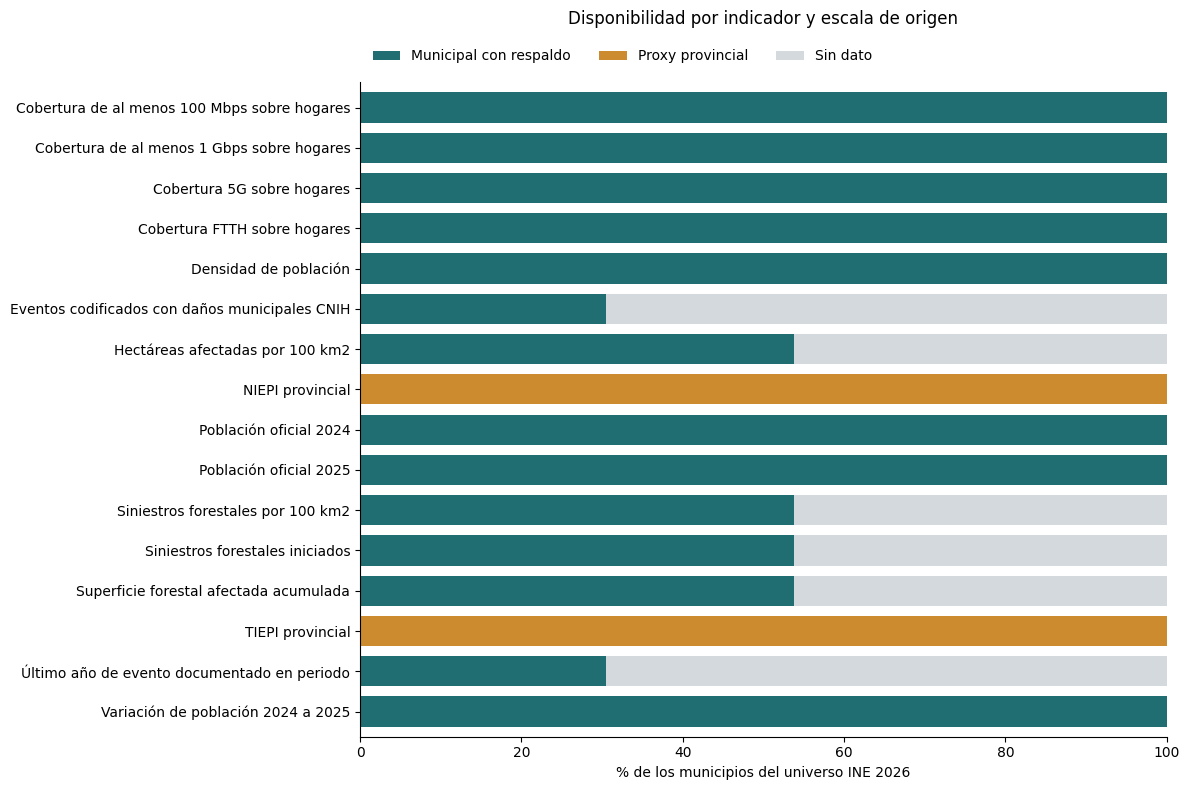

In [13]:
graf = calidad.set_index('id_indicador')[['real','aproximado','pendiente']] / N * 100
nombres = indicadores.set_index('id_indicador').nombre
fig, ax = plt.subplots(figsize=(12,8))
graf.rename(index=nombres.to_dict()).plot.barh(stacked=True, ax=ax, color=['#216e72','#cc8b2e','#d4d9dd'], width=.75)
ax.set_xlim(0,100)
ax.set_xlabel('% de los municipios del universo INE 2026')
ax.set_ylabel('')
ax.set_title('Disponibilidad por indicador y escala de origen', pad=42)
ax.legend(['Municipal con respaldo','Proxy provincial','Sin dato'], loc='lower left', bbox_to_anchor=(0,1.01), ncol=3, frameon=False)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(QA / 'cobertura_indicadores.png', dpi=160, bbox_inches='tight')
display(fig)
plt.close(fig)

### Comprobar la cobertura temporal del histórico de inundaciones

Las barras con cero indican **ausencia de eventos codificados en esta instantánea para ese año**, no ausencia real de inundaciones en España. Por eso no calculamos una probabilidad ni rellenamos municipios con cero. La tabla de vínculos exportada permite auditar cada recuento.

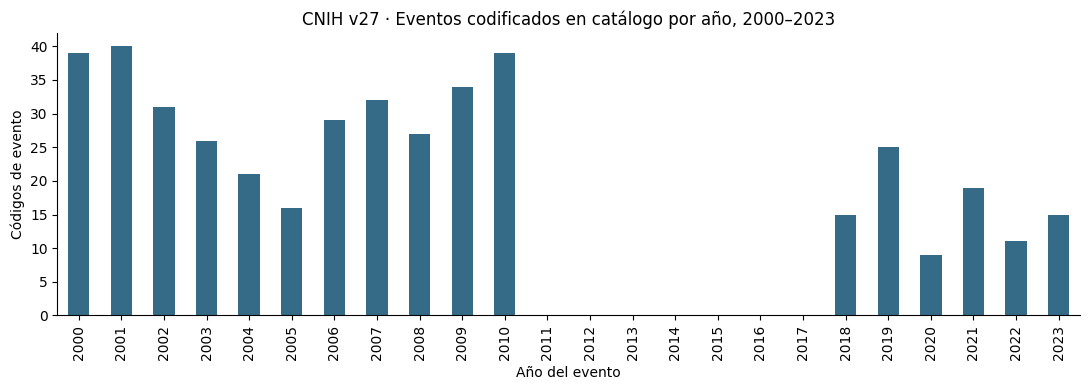

Años sin registros en el catálogo dentro de la ventana: [2011, 2012, 2013, 2014, 2015, 2016, 2017]


In [14]:
fig, ax = plt.subplots(figsize=(11,4))
serie_eventos.plot.bar(ax=ax, color='#356b87')
ax.set_title('CNIH v27 · Eventos codificados en catálogo por año, 2000–2023')
ax.set_xlabel('Año del evento')
ax.set_ylabel('Códigos de evento')
fig.tight_layout()
fig.savefig(QA / 'cnih_cobertura_temporal.png', dpi=160, bbox_inches='tight')
display(fig)
plt.close(fig)
print('Años sin registros en el catálogo dentro de la ventana:', serie_eventos.index[serie_eventos.eq(0)].tolist())

## 13 · Matriz para exploración y entrega a ML

Se entrega la tabla ancha con todos los indicadores y una matriz base de contexto e infraestructura con cobertura completa, si los controles lo confirman. **No se rellenan huecos con medias o ceros.** La persona de ML decidirá imputación, escalado, PCA y evaluación según el objetivo.

La matriz base propuesta usa densidad, variación de población, FTTH, 5G y TIEPI provincial. Es una selección inicial para explorar perfiles territoriales, no un modelo de riesgo compuesto. Evita duplicar población total y densidad, varias velocidades de cobertura muy correlacionadas y TIEPI/NIEPI a la vez. El proxy provincial repetido puede introducir agrupaciones por provincia; debe evaluarse con y sin él.

Los históricos de incendios e inundaciones siguen disponibles con sus nulos y advertencias. No se fuerzan al clustering hasta resolver sesgos de cobertura y periodos. No se incluye el código INE como variable numérica ni latitud/longitud salvo decisión metodológica explícita.

In [15]:
features_base = ['densidad_hab_km2','variacion_poblacion_pct','cobertura_ftth_pct','cobertura_5g_pct','tiepi_horas_prov_2021']
matriz_base = dataset[['cod_ine',*features_base]].copy()
print('Municipios con todos los campos de la matriz base:', int(matriz_base[features_base].notna().all(axis=1).sum()), '/', N)
# No eliminar filas silenciosamente. El estado y el informe de calidad acompañan la matriz.
matriz_todos = dataset[['cod_ine',*IDs]].copy()
display(matriz_base.head())

Municipios con todos los campos de la matriz base: 8132 / 8132


,cod_ine,densidad_hab_km2,variacion_poblacion_pct,cobertura_ftth_pct,cobertura_5g_pct,tiepi_horas_prov_2021
0,01051,137.367993,0.659554,98.928397,99.975822,0.67
1,01001,148.154003,-0.538539,98.776224,68.958003,0.67
2,01002,107.654915,0.329138,95.017964,100.000000,0.67
3,01049,6.429927,-0.704225,74.157303,100.000000,0.67
4,01003,18.515808,-1.955105,86.751361,99.840710,0.67


## 14 · Exportar los resultados

CSV se guarda con UTF-8 BOM para facilitar su apertura en Excel; los decimales usan punto. **Al leer códigos con pandas usa `dtype={'cod_ine': str, 'cod_provincia': str}`**. El formato Parquet conserva mejor tipos y se incluye si `pyarrow` está instalado.

El GeoJSON contiene únicamente identificación, punto de ficha y geometría. El frontend puede unirlo con las puntuaciones futuras por `cod_ine`. No se añade ninguna puntuación ficticia ni peso decidido por el notebook.

Se exporta también un resumen municipal de disponibilidad (`n_indicadores_con_dato`, `n_proxies_provinciales`). Es un recuento de cobertura, no una confianza estadística ni una garantía de aptitud.

In [16]:
def guardar_csv(tabla, nombre, carpeta=OUT):
    tabla.to_csv(carpeta / nombre, index=False, encoding='utf-8-sig')

guardar_csv(municipios, 'municipios.csv')
guardar_csv(indicadores, 'indicadores.csv')
guardar_csv(valores, 'valores.csv')
guardar_csv(dataset, 'dataset_municipal.csv')
guardar_csv(matriz_todos, 'matriz_todos_indicadores.csv')
guardar_csv(matriz_base, 'matriz_base_contexto_infraestructura.csv')
guardar_csv(elec, 'electricidad_provincial_2021.csv')
guardar_csv(calidad, 'calidad_indicadores.csv', QA)
guardar_csv(reporte_cruces, 'auditoria_cruces.csv', QA)
guardar_csv(reporte_incidencias, 'incidencias.csv', QA)
guardar_csv(catalogo_fuentes, 'fuentes.csv', QA)
disponibilidad = valores.groupby('cod_ine').agg(n_indicadores_con_dato=('valor', 'count'), n_indicadores=('id_indicador','size'))
disponibilidad['n_proxies_provinciales'] = valores.estado.eq('aproximado').groupby(valores.cod_ine).sum()
guardar_csv(disponibilidad.reset_index(), 'disponibilidad_municipal.csv')
features_geo = []
for fila in municipios.to_dict('records'):
    geom = geometrias.get(fila['cod_ine'])
    if geom is not None:
        features_geo.append({'type':'Feature','id':fila['cod_ine'],
            'properties': {k:fila[k] for k in ['cod_ine','nombre','cod_provincia','provincia','ccaa','superficie_km2','lat','lon']},
            'geometry':geom})
(OUT / 'municipios.geojson').write_text(json.dumps({'type':'FeatureCollection','name':'SiteWise_municipios_GISCO_2024',
    'attribution':'Eurostat GISCO · © EuroGeographics para los límites administrativos', 'features':features_geo}, ensure_ascii=False, separators=(',',':')), encoding='utf-8')
try:
    import pyarrow
except ImportError:
    print('Parquet omitido: instala pyarrow si lo necesitas. Los CSV y GeoJSON están completos.')
else:
    for nombre,tabla in [('municipios',municipios),('valores',valores),('dataset_municipal',dataset)]:
        tabla.to_parquet(OUT / (nombre+'.parquet'), index=False)
# Comprobación de lectura para garantizar códigos y tamaño de la entrega.
releido = pd.read_csv(OUT/'dataset_municipal.csv', dtype={'cod_ine':str,'cod_provincia':str})
assert len(releido)==N and releido.cod_ine.str.fullmatch(r'\d{5}').all()
assert releido.cod_ine.is_unique
salidas = [{'archivo':str(p.relative_to(ROOT)), 'bytes':p.stat().st_size, 'sha256':sha256(p)} for p in OUT.iterdir() if p.is_file() and p.name!='manifest_salidas.json']
(OUT/'manifest_salidas.json').write_text(json.dumps({'version':'0.1.0','ejecutado_utc':datetime.now(timezone.utc).isoformat(),
    'municipios':N,'indicadores':len(IDs),'filas_valores':len(valores),'archivos':salidas},ensure_ascii=False,indent=2),encoding='utf-8')
print('Exportación terminada:', OUT)
display(pd.DataFrame(salidas)[['archivo','bytes']])

Exportación terminada: c:\PROYECTOS_ELE\Final_sidewise\data\processed\sitewise_v01


,archivo,bytes
0,data\processed\sitewise_v01\cnih_vinculos_muni...,170324
1,data\processed\sitewise_v01\dataset_municipal.csv,4257173
2,data\processed\sitewise_v01\dataset_municipal....,947879
3,data\processed\sitewise_v01\disponibilidad_mun...,122052
4,data\processed\sitewise_v01\electricidad_provi...,823
5,data\processed\sitewise_v01\indicadores.csv,7449
6,data\processed\sitewise_v01\matriz_base_contex...,646290
7,data\processed\sitewise_v01\matriz_todos_indic...,1298626
8,data\processed\sitewise_v01\municipios.csv,833439
9,data\processed\sitewise_v01\municipios.geojson,11136594


## 15 · Resumen observado y límites para el proyecto

La celda siguiente usa únicamente resultados ejecutados. Las incidencias y fuentes se guardan junto a la entrega. Los porcentajes de cobertura no miden exactitud, actualidad o confianza de la recomendación.

In [17]:
cobertura_fuego = calidad.set_index('id_indicador').loc['siniestros_forestales_2006_2015_n','cobertura_pct']
cobertura_cnih = calidad.set_index('id_indicador').loc['eventos_cnih_2000_2023_n','cobertura_pct']
texto = f"""### Resultado de la ejecución

- **{format(N, ',').replace(',', '.')} municipios**, {len(IDs)} indicadores y {format(len(valores), ',').replace(',', '.')} observaciones municipio–indicador.
- Población INE 2024–2025, conectividad 2025 y geometrías cruzadas con controles por código.
- Electricidad: {len(elec)} valores provinciales de 2021 por índice, replicados y etiquetados como aproximados.
- Incendios: datos publicados para {len(fuego):,} municipios ({cobertura_fuego:.1f}% del universo).
- Inundaciones: vínculos documentados en 2000–2023 para {len(cnih):,} municipios ({cobertura_cnih:.1f}%).
- CNIH: correcciones y exclusiones de códigos documentadas por fila; no se acepta un código incompatible con el nombre.
- {len(reporte_incidencias):,} incidencias registradas y {len(reporte_cruces)} cruces auditados.

### Lo que esta versión todavía no puede afirmar

No determina si una parcela o municipio cumple todos los mínimos de una industria. No cubre aún exposición a inundación SNCZI, sismicidad validada, radiación solar, acceso real a autovías y mercancías, agua, suelo industrial ni personal cualificado. No presenta los antiguos históricos como mediciones actuales. No hay pesos, notas ni ranking de inversión fabricados.

Para una primera actividad solar hace falta, al menos, incorporar y validar el recurso solar y sus restricciones antes de declarar aptitud. Para logística, las conexiones de transporte son igualmente necesarias. La tabla actual sirve como base real para ampliar, comparar variables disponibles y ensayar la integración.
"""
display(Markdown(texto))
(QA/'resumen_dataset.md').write_text(texto,encoding='utf-8')
# Registrar entorno real, sin adivinar versiones.
import importlib.metadata as versionado
paquetes = ['pandas','numpy','openpyxl','matplotlib','shapely','nbformat','nbclient','ipykernel']
_ = (QA/'entorno_ejecucion.json').write_text(json.dumps({'python':platform.python_version(), 'paquetes':{p:versionado.version(p) for p in paquetes}},indent=2),encoding='utf-8')

### Resultado de la ejecución

- **8.132 municipios**, 16 indicadores y 130.112 observaciones municipio–indicador.
- Población INE 2024–2025, conectividad 2025 y geometrías cruzadas con controles por código.
- Electricidad: 52 valores provinciales de 2021 por índice, replicados y etiquetados como aproximados.
- Incendios: datos publicados para 4,375 municipios (53.8% del universo).
- Inundaciones: vínculos documentados en 2000–2023 para 2,480 municipios (30.5%).
- CNIH: correcciones y exclusiones de códigos documentadas por fila; no se acepta un código incompatible con el nombre.
- 2,806 incidencias registradas y 6 cruces auditados.

### Lo que esta versión todavía no puede afirmar

No determina si una parcela o municipio cumple todos los mínimos de una industria. No cubre aún exposición a inundación SNCZI, sismicidad validada, radiación solar, acceso real a autovías y mercancías, agua, suelo industrial ni personal cualificado. No presenta los antiguos históricos como mediciones actuales. No hay pesos, notas ni ranking de inversión fabricados.

Para una primera actividad solar hace falta, al menos, incorporar y validar el recurso solar y sus restricciones antes de declarar aptitud. Para logística, las conexiones de transporte son igualmente necesarias. La tabla actual sirve como base real para ampliar, comparar variables disponibles y ensayar la integración.


## 16 · Reconstrucción de fuentes y siguientes incorporaciones

### Volver a obtener población desde el INE

Los identificadores de las 52 tablas se conservan en `ine_tablas_poblacion.json` y en la página oficial descargada. Cada archivo tiene su URL reproducible:

```python
url = f"https://servicios.ine.es/wstempus/js/ES/DATOS_TABLA/{tabla}?nult=2&tip=AM"
```

`nult=2` es una consulta móvil: en el futuro puede devolver otros años. **Para reproducir esta versión utiliza las instantáneas incluidas y sus hashes**; para actualizar, guarda nueva versión y revisa los años antes de ejecutar. No renombres datos 2026 como si fueran 2025.

### Reconstruir las exportaciones de Access

1. Descarga el ZIP oficial indicado en el manifiesto y extrae el `.accdb` en una carpeta temporal.
2. Con `mdbtools` instalado (Linux/macOS), ejecuta `mdb-export CNIH_Eventos_Inundacion_v27.accdb CNIH_EVENTO > CNIH_EVENTO.csv` y repite para las tablas enumeradas en `conversion_cnih` del manifiesto.
3. En Windows puedes usar Microsoft Access o un driver Access ODBC compatible con tu Python para exportar las mismas tablas **completas**, sin filtros ni cambios de encabezados. No basta convertir un informe resumen.
4. Verifica hashes/filas, documenta las diferencias de serialización y crea una nueva versión del manifiesto si cambia la exportación. El notebook no ejecuta formularios ni macros de Access.

### Reconstruir la geometría

Descarga el GeoJSON europeo de GISCO que consta en el manifiesto, filtra `properties.CNTR_CODE == 'ES'` y conserva todas sus propiedades/geometrías. El archivo europeo ocupa aproximadamente 150 MB; el paquete incluye solo España. La cartografía está generalizada y no sustituye delimitación catastral.

### Añadir una tabla provincial sin inventar datos municipales

Utiliza el código provincial, valida una fila por provincia y periodo y realiza `municipios.merge(tabla_provincial, on='cod_provincia', how='left', validate='many_to_one')`. Registra `nivel_origen='provincia'` y `estado='aproximado'`. Nunca sumes medias provinciales ni llames observado municipal a ese resultado. Una fuente exclusivamente autonómica queda descartada para indicadores.

### Pendientes que necesitan otras entradas

- **SNCZI y límites de cobertura:** para porcentaje inundable se necesitan los polígonos, el escenario de retorno y la delimitación de zonas estudiadas. Fuera de zonas estudiadas no se presupone riesgo cero.
- **Carreteras y mercancías:** accesos a autovías y terminales de carga, no estaciones genéricas como sustituto silencioso. Distancia desde un punto de ficha es un proxy que hay que etiquetar.
- **Radiación solar / viento, agua, suelo industrial y personal:** fuentes específicas, periodo y método por actividad. No se derivan de población o de cobertura digital.
- **Sismicidad:** verificar el documento normativo y sus listas antes de cargar indicadores binarios. No se han creado ceros para municipios sin fuente.

No necesitas buscar un archivo que ya esté en esta entrega. Los nuevos archivos deben acompañarse de URL, organismo, periodo, unidad y nivel territorial.